In [23]:
import torch, numpy as np, time
from torch.utils.data import DataLoader, random_split, ConcatDataset
from torchvision import datasets, transforms
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
import kagglehub
from kagglehub import KaggleDatasetAdapter
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.nn.functional as F

from torchmetrics.classification import MulticlassAccuracy

acc = MulticlassAccuracy(num_classes=10).to(dev)

torch.manual_seed(42); np.random.seed(42)
dev = "cuda" if torch.cuda.is_available() else "cpu"

tf = transforms.ToTensor()  # range [0,1]; pakai Sigmoid di output
full = ConcatDataset([datasets.FashionMNIST("data", True, tf, download=True),
                      datasets.FashionMNIST("data", False, tf, download=True)])
n = len(full); n_tr, n_va = int(.8*n), int(.1*n)
tr, va, te = random_split(full, [n_tr, n_va, n-n_tr-n_va],
                          generator=torch.Generator().manual_seed(42))
tr_dl = DataLoader(tr, 128, shuffle=True)
va_dl = DataLoader(va, 128); te_dl = DataLoader(te, 128)

psnr = PeakSignalNoiseRatio(data_range=1.0).to(dev)
ssim = StructuralSimilarityIndexMeasure(data_range=1.0).to(dev)

@torch.no_grad()
def eval_recon(model_fn, dl):  # model_fn(x) -> x_hat
    mse = 0; psnr.reset(); ssim.reset(); cnt = 0
    for x, _ in dl:
        x = x.to(dev); xh = model_fn(x)
        mse += ((x-xh)**2).mean().item()*len(x); cnt += len(x)
        psnr.update(xh, x); ssim.update(xh, x)
    return mse/cnt, psnr.compute().item(), ssim.compute().item()

@torch.no_grad()
def latency_ms(fn, runs=50):  # fn() menghasilkan 64 sampel
    for _ in range(5): fn()
    if dev == "cuda": torch.cuda.synchronize()
    t = time.time()
    for _ in range(runs): fn()
    if dev == "cuda": torch.cuda.synchronize()
    return (time.time()-t)/runs*1000

In [9]:
import collections

x, y = next(iter(tr_dl))
print(x.shape, x.min().item(), x.max().item())   # [128,1,28,28], 0.0, 1.0
print(torch.isnan(x).any().item())                # False

print(len(tr), len(va), len(te))                  # 56000, 7000, 7000
cnt = collections.Counter(int(l) for _, l in te)
print(sorted(cnt.items()))                        # tiap kelas ~700, harus seimbang

torch.Size([128, 1, 28, 28]) 0.0 1.0
False
56000 7000 7000
[(0, 700), (1, 659), (2, 708), (3, 714), (4, 707), (5, 660), (6, 685), (7, 706), (8, 738), (9, 723)]


In [13]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)
    def features(self, x):
        x = x.view(x.size(0),-1)
        h1 = F.relu(self.fc1(x))
        z = F.relu(self.fc2(h1))
        return z
    def forward(self, x):
        return self.fc3(self.features(x))
    
model = MLP().to(dev)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
crit = nn.CrossEntropyLoss()

In [14]:
for epoch in range (12):
    model.train()
    for x,y in tr_dl:
        x, y = x.to(dev), y.to(dev)
        opt.zero_grad()
        logits = model(x)
        loss = crit(logits, y)
        loss.backward()
        opt.step()

In [16]:
model.eval(); acc.reset()
with torch.no_grad():
    for x,y in va_dl:
        x, y = x.to(dev), y.to(dev)
        acc.update(model(x), y)
    print("acc:", acc.compute().item())

acc: 0.8886488676071167


In [20]:
w1, w2, w3 = model.fc1.weight, model.fc2.weight, model.fc3.weight
print(w1.shape, w2.shape, w3.shape)

torch.Size([256, 784]) torch.Size([64, 256]) torch.Size([10, 64])


In [21]:
@torch.no_grad()
def topdown_from_class():
    y = torch.eye(10, device=dev)
    z_hat = F.relu(y @ w3)
    h1_hat = F.relu(z_hat @ w2)
    x_hat = F.relu(h1_hat @ w1)
    return x_hat.view(-1, 1, 28, 28)

In [22]:
@torch.no_grad()
def project_from_latent(x):
    z = model.features(x.to(dev))
    h1_hat = F.relu(z @ w2)
    x_hat = F.relu(h1_hat @ w1)
    return x_hat.view(-1, 1, 28, 28)

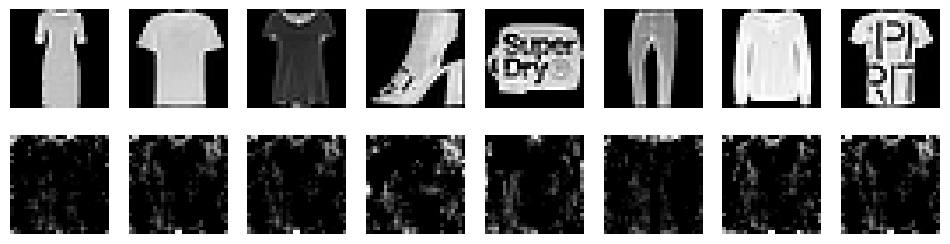

In [26]:
x, _ = next(iter(te_dl)); x = x[:8]
xh = project_from_latent(x).cpu()
fig, ax = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    ax[0, i].imshow(x[i, 0], cmap="gray"); ax[0,i].axis("off")
    ax[1, i].imshow(xh[i, 0], cmap="gray"); ax[1,i].axis("off")
plt.show()

In [29]:
for p in model.parameters(): p.requiers_grad = False
model.eval()

dec = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()).to(dev)
opt_d = torch.optim.Adam(dec.parameters(), lr=1e-3)
for epoch in range(10):
    for x, y in tr_dl:
        x = x.to(dev)
        with torch.no_grad():
            z = model.features(x)
        loss = F.mse_loss(dec(z), x.view(x.size(0), -1))
        opt_d.zero_grad(); loss.backward(); opt_d.step()
        print(epoch, loss.item())

print(eval_recon(lambda x: dec(model.features(x)).view(-1, 1, 28, 28), te_dl))

0 0.1892273873090744
0 0.17690759897232056
0 0.15808330476284027
0 0.14215002954006195
0 0.13216549158096313
0 0.12261546403169632
0 0.10762196034193039
0 0.10034307837486267
0 0.09003298729658127
0 0.09044536203145981
0 0.08496074378490448
0 0.07820004969835281
0 0.07692481577396393
0 0.06989271938800812
0 0.06695438176393509
0 0.07037540525197983
0 0.06243043765425682
0 0.06206781789660454
0 0.06344574689865112
0 0.06156587600708008
0 0.06272804737091064
0 0.05865054950118065
0 0.06433357298374176
0 0.0548991821706295
0 0.05606207624077797
0 0.05667562410235405
0 0.052478015422821045
0 0.051104627549648285
0 0.05362116917967796
0 0.054236672818660736
0 0.056685734540224075
0 0.048689063638448715
0 0.050429731607437134
0 0.04769519343972206
0 0.05244997888803482
0 0.05186851695179939
0 0.0492476224899292
0 0.04495969042181969
0 0.04430477321147919
0 0.04786918684840202
0 0.047314777970314026
0 0.04914895445108414
0 0.0494130477309227
0 0.04830002784729004
0 0.04265575110912323
0 0.043

In [31]:
with torch.no_grad():
    Z = torch.cat([model.features(x.to(dev)) for x, _ in te_dl])   # [7000, 64]
    mu, sigma = Z.mean(0), Z.std(0)                                # std per dimensi
    z_rand = mu + sigma * torch.randn(16, 64, device=dev)          # N(mu, diag(sigma^2))
    samples = dec(z_rand).view(-1, 1, 28, 28).cpu()